# Refined products demand — 02 Research & results

**Question.** Can a gradient-boosted tree, fed lagged demand and macro predictors, forecast monthly demand for a refined product up to twelve months ahead better than a simple time series?

Three products, one per part of the barrel, each where demand is measured directly: **US gasoline** and **US distillate fuel oil** (EIA product supplied, kb/d) and **Singapore bunker fuel oil** (MPA sales, kt/day).

This notebook reads the point-in-time dataset built in `01_data.ipynb` and the walk-forward backtests written by `python -m src.model`. It performs no data operation of its own.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

from src import config as c, data, model, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": .3})

products = list(c.DEMAND_LAG)
TITLES = {"gasoline": "US gasoline, kb/d", "distillate": "US distillate fuel oil, kb/d", "bunker": "Singapore bunker fuel oil, kt/day"}
STYLE = {"xgboost": dict(color="C1"), "naive": dict(color="C0", ls="--"), "last": dict(color="0.5", ls=":")}

In [2]:
datasets = {p: data.dataset(p) for p in products}   # the panel of notebook 01
bt = sql.query("SELECT * FROM backtest")             # one row per product, forecast origin and horizon
marked = model.scored(bt)                            # target published, and no 2020 in the origin, target or reference

## 1. Key findings

In [3]:
# WAPE in %, averaged over the twelve horizons: the model against its two free benchmarks
headline = pd.DataFrame({p: model.wape(bt[bt["product"] == p]) for p in products}).T
headline.columns = ["xgboost", "seasonal naive", "last value"]
headline["gain on seasonal naive, %"] = 100 * (1 - headline["xgboost"] / headline["seasonal naive"])
headline["gain on best benchmark, %"] = 100 * (1 - headline["xgboost"] / headline[["seasonal naive", "last value"]].min(axis=1))
headline["forecast origins"] = marked.groupby("product")["origin"].nunique()
print(f"walk-forward backtest, monthly origins {marked['origin'].min():%b %Y} to {marked['origin'].max():%b %Y}, WAPE %")
headline

walk-forward backtest, monthly origins Jan 2015 to Aug 2026, WAPE %


,xgboost,seasonal naive,last value,"gain on seasonal naive, %","gain on best benchmark, %",forecast origins
gasoline,1.77,1.82,3.53,2.83,2.83,125
distillate,3.77,3.84,4.57,2.02,2.02,125
bunker,6.91,6.81,6.10,-1.52,-13.35,126


Data through the download of 15 November 2026; 125 monthly forecast origins per product, January 2015 to August 2026, twelve horizons each.

1. **XGBoost does not provide a forecasting edge worth the name.** On US gasoline it scores 1.77% against 1.82% for the seasonal naive, on US distillate 3.77% against 3.84%. Both gaps are the size of the model's own seed noise (0.05 points, section 7).
2. **On Singapore bunker fuel oil it is worse than both benchmarks.** 6.91% against 6.81% for the seasonal naive and 6.10% for simply holding the last published value, which is the benchmark to beat on a trending series.
3. **Where the model helps, it is a nowcast.** The gain sits at one to two months ahead (distillate 3.19% against 3.65% at one month) and disappears from seven months out, where the model is slightly worse than the naive.
4. **The macro predictors matter as a group for distillate only.** Without them the distillate error rises by 0.33 points, six times the seed noise; for gasoline they add nothing measurable and for bunker they make the forecast worse. No single driver stands out.
5. **Answer to the question: no, not at twelve months.** A seasonal naive, or the last value for bunker, is as good and far cheaper. The model is defensible only as a short-horizon adjustment for the two US products.

## 2. The forecasting problem

- **Target.** Monthly demand, as published by the source.
- **Origin.** The last day of month *t*. The information set is everything published by then: demand up to *t − lag* (EIA publishes two months late, MPA one) and each driver as aligned in notebook 01.
- **Horizon.** Months *t+1* to *t+12*, forecast directly: one model per step, each trained on its own target, never a forecast fed back as an input.
- **Benchmarks.** *Seasonal naive*: the same calendar month in the latest year already published at the origin. *Last value*: the newest published print, held flat. Both are free and use the same information set.
- **Model.** `XGBRegressor` on the log deviation from the seasonal naive, `y = log demand(t+step) − log naive`. The forecast is the naive times `exp(prediction)`. A tree cannot extrapolate a level it has never seen; a deviation from last year it can. If the model learns nothing it predicts zero and returns the naive.
- **Evaluation.** Expanding-window walk-forward: at every month end since January 2015 the twelve models are refitted on what was published by then, and the forecasts are marked later against the published outcome. MAE and RMSE in the unit of demand; WAPE (sum of absolute errors over sum of actuals) to compare products; bias.

In [4]:
# one past origin, used for the walk-through below: everything published by 31 December 2023
df, lag = datasets["distillate"], c.DEMAND_LAG["distillate"]
origin = pd.Timestamp("2023-12-01")
months = pd.date_range(origin + pd.DateOffset(months=1), periods=model.HORIZON, freq="MS", name="target month")
reference = [m - pd.DateOffset(months=model.back(step, lag)) for step, m in enumerate(months, 1)]
print(f"newest demand print at the origin: {origin - pd.DateOffset(months=lag):%B %Y}")
pd.DataFrame({"step": range(1, model.HORIZON + 1), "seasonal naive repeats": reference}, index=months)

newest demand print at the origin: October 2023


,step,seasonal naive repeats
target month,,
2024-01-01,1,2023-01-01
2024-02-01,2,2023-02-01
2024-03-01,3,2023-03-01
2024-04-01,4,2023-04-01
2024-05-01,5,2023-05-01
2024-06-01,6,2023-06-01
2024-07-01,7,2023-07-01
2024-08-01,8,2023-08-01
2024-09-01,9,2023-09-01


Steps 11 and 12 reach back two years: at the end of December 2023 the figures for November and December 2023 are not out yet. A naive that used them would be looking ahead.

## 3. Demand: level, seasonality, persistence

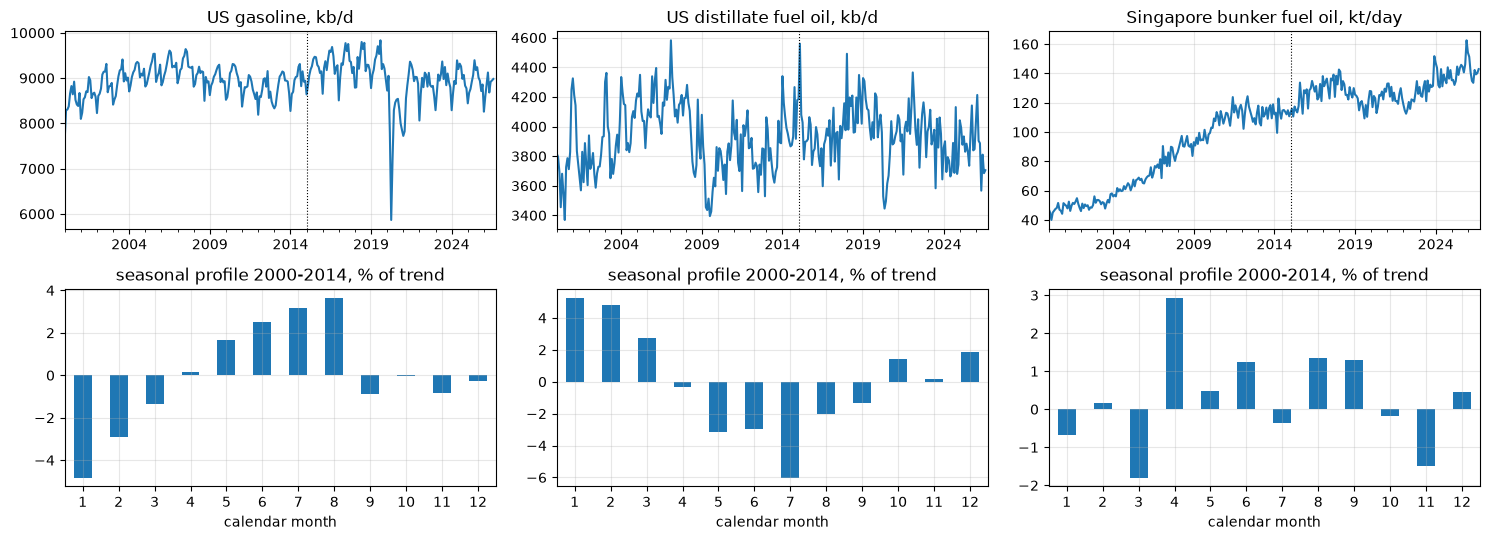

In [5]:
demand = pd.DataFrame({p: datasets[p]["demand"] for p in products})
history = demand[demand.index < c.BACKTEST_START]  # only what precedes the backtest informs the design

# seasonal profile: each month against its centred twelve-month average, in %
profile = 100 * (history / history.rolling(12, center=True).mean() - 1)
profile = profile.groupby(profile.index.month).mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 5.5))
for i, p in enumerate(products):
    demand[p].plot(ax=axes[0, i], title=TITLES[p])
    axes[0, i].axvline(pd.Timestamp(c.BACKTEST_START), color="k", lw=.8, ls=":")
    axes[0, i].set_xlabel("")
    profile[p].plot.bar(ax=axes[1, i], rot=0, title="seasonal profile 2000-2014, % of trend")
    axes[1, i].set_xlabel("calendar month")
plt.tight_layout();

In [6]:
# persistence before the backtest: autocorrelation of the level and of the year-on-year log change
yoy = np.log(history).diff(12)
pd.DataFrame({"level, 1 month": history.apply(lambda s: s.autocorr(1)),
              "level, 12 months": history.apply(lambda s: s.autocorr(12)),
              "year-on-year, 1 month": yoy.apply(lambda s: s.autocorr(1)),
              "year-on-year, 12 months": yoy.apply(lambda s: s.autocorr(12)),
              "seasonal swing, % of trend": profile.max() - profile.min()})

,"level, 1 month","level, 12 months","year-on-year, 1 month","year-on-year, 12 months","seasonal swing, % of trend"
gasoline,0.75,0.81,0.56,-0.02,8.46
distillate,0.72,0.54,0.66,-0.17,11.26
bunker,0.98,0.97,0.37,-0.07,4.73


In [7]:
# share of backtest months above anything seen before 2015: levels a tree trained on levels could not reach
(demand[demand.index >= c.BACKTEST_START] > history.max()).mean().rename("above the pre-2015 maximum").to_frame().T

,gasoline,distillate,bunker
above the pre-2015 maximum,0.05,0.00,0.65


- **The two US products are seasonal and flat.** Gasoline swings 8% around its trend between winter and summer, distillate 11% the other way round, and neither has left its pre-2015 range in any lasting way. Last year's same month is a strong forecast, which is why the seasonal naive is the benchmark.
- **Singapore bunker is a trend with little seasonality.** The level is almost perfectly persistent (0.98) and 65% of the backtest months are above anything seen before 2015. The newest print is the natural benchmark there, and a model that predicted levels could not have reached them.
- **Year-on-year changes carry short memory only.** Their autocorrelation is 0.4 to 0.7 at one month and nil at twelve: whatever a model learns from recent growth should help at short horizons and fade.

## 4. Features

Everything enters in year-on-year terms, so the model sees growth rather than levels: the last twelve published demand prints (`yoy_lag`), and each driver as readable at the origin against its value a year earlier. Heating degree days enter as a difference, because they fall to almost zero in summer.

In [8]:
X, y = model.features(df, lag, step=12)
X.loc[[origin]].T.rename(columns=lambda t: f"origin {t:%b %Y}").T  # one row: the information set at the origin

,yoy_lag2,yoy_lag3,yoy_lag4,yoy_lag5,yoy_lag6,yoy_lag7,yoy_lag8,yoy_lag9,yoy_lag10,yoy_lag11,yoy_lag12,yoy_lag13,hdd,hdd_oil,ind,ind_manuf,product_supplied_4wk,real_price,truck
month,,,,,,,,,,,,,,,,,,,
origin Dec 2023,-0.02,-0.06,0.03,-0.04,-0.02,0.01,-0.02,-0.02,-0.09,-0.04,-0.04,-0.03,-13.00,97.00,-0.00,-0.00,0.01,-0.24,-0.04


In [9]:
# the target at this origin by hand: log of December 2024 over December 2022, the naive's reference
target = origin + pd.DateOffset(months=12)
by_hand = np.log(df.loc[target, "demand"] / df.loc[target - pd.DateOffset(months=model.back(12, lag)), "demand"])
assert abs(by_hand - y.loc[origin]) < 1e-12
by_hand

np.float64(-0.01326983378446999)

In [10]:
# what each driver on that row describes, and when it was published: read from the stored panel
info = sql.query(f"""
    SELECT variable, period_end, available_at, month_end AS origin
    FROM panel WHERE product = 'distillate' AND month = DATE '{origin:%Y-%m-%d}' ORDER BY variable
""")
assert (info["available_at"] <= info["origin"]).all()
info

,variable,period_end,available_at,origin
0,hdd,2023-11-30,2023-12-31,2023-12-31
1,hdd_oil,2023-11-30,2023-12-31,2023-12-31
2,ind,2023-11-30,2023-12-31,2023-12-31
3,ind_manuf,2023-11-30,2023-12-31,2023-12-31
4,product_supplied_4wk,2023-12-22,2023-12-28,2023-12-31
5,real_price,2023-11-30,2023-12-31,2023-12-31
6,truck,2023-09-30,2023-12-31,2023-12-31


## 5. Training and tuning without look-ahead

**Training rows.** A row can be used at an origin only if its *target* had been published by then. For the twelve-month model that removes the last fourteen months before the origin, not twelve. Rows whose origin, target or naive reference falls in 2020 are left out of training (`EXCLUDE_YEARS`): the model is not asked to learn a lockdown.

In [11]:
rows = model.trainable(y, step=12, lag=lag, origin=origin)
last = X.index[rows].max()
assert last + pd.DateOffset(months=12 + lag) <= origin  # its target was published by the origin
pd.DataFrame({"training rows": [rows.sum()], "first origin": [X.index[rows].min()], "last origin": [last],
              "its target month": [last + pd.DateOffset(months=12)],
              "target published by the end of": [last + pd.DateOffset(months=12 + lag)]})

,training rows,first origin,last origin,its target month,target published by the end of
0,226,2001-01-01,2022-10-01,2023-10-01,2023-12-01


In [12]:
# one model per horizon, each with its own training rows
pd.Series({step: model.trainable(model.features(df, lag, step)[1], step, lag, origin).sum()
           for step in range(1, model.HORIZON + 1)}).rename_axis("step").rename("training rows").to_frame().T

step,1,2,3,4,5,6,7,8,9,10,11,12
training rows,249,248,247,246,245,244,243,242,241,240,227,226


**Tuning.** Eight parameter sets, chosen once per product at the first backtest origin (January 2015) by expanding-window cross-validation on the data published by then. The backtest years play no part in the choice. The grid is small on purpose: with some 150 monthly rows a large search would select noise.

In [13]:
# the folds as the backtest saw them at its first origin: train on targets published before each block
first = pd.Timestamp(c.BACKTEST_START)
fit_rows = model.trainable(y, 12, lag, first)
fit_X, fit_y = X[fit_rows], y[fit_rows]
edges = [len(fit_X) * k // 4 for k in range(5)]
for k, (a, b) in enumerate(zip(edges[1:-1], edges[2:]), 1):
    train = fit_X.index[fit_X.index + pd.DateOffset(months=12 + lag) <= fit_X.index[a]]
    print(f"fold {k}   train {train[0]:%Y-%m} to {train[-1]:%Y-%m}   validate {fit_X.index[a]:%Y-%m} to {fit_X.index[b - 1]:%Y-%m}")

fold 1   train 2001-01 to 2003-01   validate 2004-03 to 2007-05
fold 2   train 2001-01 to 2006-04   validate 2007-06 to 2010-08
fold 3   train 2001-01 to 2009-07   validate 2010-09 to 2013-11


In [14]:
# cross-validated RMSE of the log deviation, read as a % error
cv = pd.DataFrame(model.GRID)
cv["cv rmse, %"] = [100 * np.sqrt(model.cv_score(fit_X, fit_y, 12, lag, params)) for params in model.GRID]
cv.sort_values("cv rmse, %")

,learning_rate,max_depth,n_estimators,"cv rmse, %"
1,0.03,3,600,8.41
0,0.03,3,200,8.49
3,0.03,5,600,8.49
2,0.03,5,200,8.53
6,0.10,5,200,8.56
7,0.10,5,600,8.56
5,0.10,3,600,8.82
4,0.10,3,200,8.82


In [15]:
# what the backtest stored for each product; the distillate row is the best line above
params = sql.query("SELECT * FROM params").set_index("product")
assert model.tuned("distillate") == model.tune(df, lag, first)
params

,learning_rate,max_depth,n_estimators
product,,,
gasoline,0.10,3,200
distillate,0.03,3,600
bunker,0.03,3,200


The whole grid sits between 8.4% and 8.8%: the model is not very sensitive to its tuning, which is the result one wants on a sample this small. Shallow trees and the lower learning rate win, the conservative end of the grid.

**One forecast, end to end.** From the December 2023 origin: fit twelve models, predict twelve deviations, apply them to the naive.

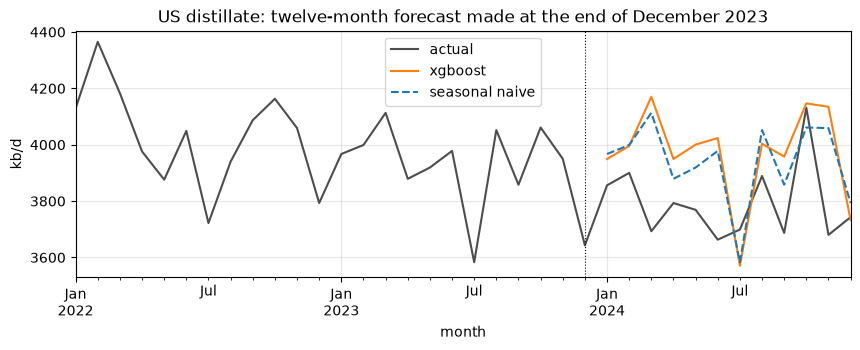

In [16]:
path = model.forecast(df, lag, origin, model.tuned("distillate"))
naive = model.seasonal_naive(df, lag, origin)
example = pd.DataFrame({"actual": df["demand"].reindex(path.index), "xgboost": path, "naive": naive})

ax = df["demand"].loc["2022":"2024"].plot(color="0.3", label="actual")
example["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
example["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
ax.axvline(origin, color="k", lw=.8, ls=":")
ax.set_title("US distillate: twelve-month forecast made at the end of December 2023"); ax.set_ylabel("kb/d"); ax.legend();

**The direct test for look-ahead.** Delete from the dataset everything that was not published at the origin, the demand prints of the last two months and every later row, and forecast again. If any step of the pipeline read the future, the forecast would change.

In [17]:
known = df.loc[:origin].copy()
known.loc[known.index > origin - pd.DateOffset(months=lag), "demand"] = np.nan  # not published yet at the origin
assert (model.forecast(known, lag, origin, model.tuned("distillate")) == path).all()

## 6. Walk-forward backtest

The same procedure from every month end since January 2015, for the three products, stored by `python -m src.model`.

In [18]:
bt[bt["product"] == "distillate"].head(12)  # one origin, twelve targets

,month,origin,step,reference,actual,xgboost,naive,last,product
1680,2015-02-01,2015-01-01,1,2014-02-01,"4,559.00","4,227.05","4,160.00","3,917.00",distillate
1681,2015-03-01,2015-01-01,2,2014-03-01,"4,078.00","4,104.63","4,066.00","3,917.00",distillate
1682,2015-04-01,2015-01-01,3,2014-04-01,"4,027.00","4,184.80","3,990.00","3,917.00",distillate
1683,2015-05-01,2015-01-01,4,2014-05-01,"3,778.00","3,933.46","3,952.00","3,917.00",distillate
1684,2015-06-01,2015-01-01,5,2014-06-01,"3,897.00","3,878.19","3,902.00","3,917.00",distillate
1685,2015-07-01,2015-01-01,6,2014-07-01,"3,901.00","3,836.48","3,866.00","3,917.00",distillate
1686,2015-08-01,2015-01-01,7,2014-08-01,"3,915.00","3,840.20","3,875.00","3,917.00",distillate
1687,2015-09-01,2015-01-01,8,2014-09-01,"4,063.00","3,831.74","3,933.00","3,917.00",distillate
1688,2015-10-01,2015-01-01,9,2014-10-01,"4,014.00","4,330.38","4,266.00","3,917.00",distillate
1689,2015-11-01,2015-01-01,10,2014-11-01,"3,740.00","3,840.47","3,917.00","3,917.00",distillate


In [19]:
# integrity of the stored backtest: every target is after its origin, and every naive reference
# had been published by the origin
def months_between(start, end):
    return (end.dt.year - start.dt.year) * 12 + end.dt.month - start.dt.month

assert (months_between(bt["origin"], bt["month"]) == bt["step"]).all()
assert (months_between(bt["reference"], bt["origin"]) >= bt["product"].map(c.DEMAND_LAG)).all()
bt.groupby("product").agg(origins=("origin", "nunique"), first_origin=("origin", "min"), last_origin=("origin", "max"),
                          forecasts=("xgboost", "count"), marked=("actual", "count"))

,origins,first_origin,last_origin,forecasts,marked
product,,,,,
bunker,141,2015-01-01,2026-09-01,1692,1614
distillate,140,2015-01-01,2026-08-01,1680,1602
gasoline,140,2015-01-01,2026-08-01,1680,1602


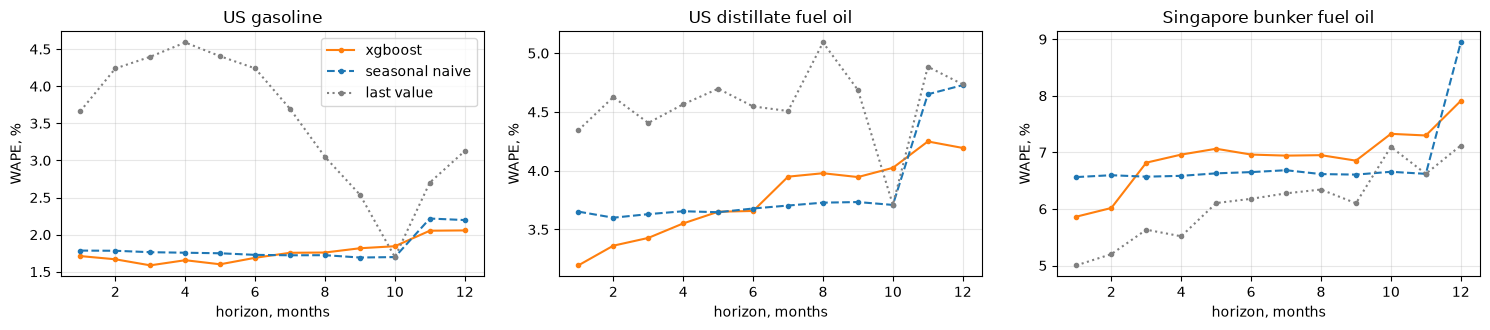

In [20]:
# error by horizon
by_step = {p: model.score(marked[marked["product"] == p]) for p in products}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, p in zip(axes, products):
    for name in model.FORECASTS:
        by_step[p]["wape"][name].plot(ax=ax, marker="o", ms=3, label={"xgboost": "xgboost", "naive": "seasonal naive", "last": "last value"}[name], **STYLE[name])
    ax.set_title(TITLES[p].split(",")[0]); ax.set_xlabel("horizon, months"); ax.set_ylabel("WAPE, %")
axes[0].legend()
plt.tight_layout();

In [21]:
# every metric, averaged over the twelve horizons. MAE and RMSE in kb/d (kt/day for bunker), WAPE and bias in %
metrics = pd.concat({p: by_step[p].mean().unstack(0) for p in products})
metrics

mae   rmse  wape  bias
gasoline   xgboost 160.82 212.23  1.77  0.53
           naive   165.52 216.10  1.82 -0.43
           last    321.27 395.08  3.53 -0.16
distillate xgboost 148.76 189.49  3.77  0.40
           naive   151.82 197.90  3.84  0.11
           last    180.41 228.19  4.57  0.28
bunker     xgboost   9.06  11.11  6.91  1.56
           naive     8.92  10.77  6.81 -2.19
           last      7.99   9.88  6.10 -1.14

- **Gasoline.** The model is ahead of the seasonal naive up to six months (1.59% against 1.76% at three months) and behind from seven to ten. MAE 161 against 166 kb/d on a market of about 9,000.
- **Distillate.** Same shape, larger at the front: 3.19% against 3.65% at one month, then no difference by five months and a deficit from seven to ten. MAE 149 against 152 kb/d.
- **Steps 11 and 12 flatter the model.** There the naive has to reach back two years (section 2) and loses half a point; the model partly corrects it. That is a weakness of the benchmark more than a skill of the model.
- **Bunker.** The model beats the seasonal naive at one and two months only, and the last value beats both at almost every horizon (5.00% at one month, 6.10% on average). The seasonal naive under-forecasts a rising series by 2.2%; the model over-forecasts by 1.6%.
- **Bias** of the model is small and positive on the US products (+0.5% and +0.4%).

In [22]:
# by target year, WAPE %. This table keeps 2020 and the months that reference it, which the headline leaves out
everything = model.scored(bt, covid=True)
everything = everything.assign(year=everything["month"].dt.year)
by_year = pd.concat({p: model.score(everything[everything["product"] == p], "year")["wape"][["xgboost", "naive"]] for p in products}, axis=1)
by_year

gasoline       distillate        bunker      
      xgboost naive    xgboost naive xgboost naive
year                                              
2015     1.27  2.60       4.28  4.01    6.33  7.54
2016     1.49  2.23       5.15  4.78    5.94  8.04
2017     1.68  1.37       2.91  3.09    4.10  6.46
2018     1.38  1.30       4.07  5.36    8.32  5.15
2019     1.37  1.26       3.12  2.75   11.23  9.25
2020    15.42 15.74       6.23  8.65    5.75  5.81
2021    10.76 11.64       4.86  5.50    5.84  4.84
2022     4.34  4.38       3.03  3.70    9.20  5.64
2023     1.72  1.75       2.94  3.38    7.29  8.17
2024     1.79  1.36       4.49  4.83    4.52  6.76
2025     1.29  1.33       3.38  3.61    5.91  5.68
2026     2.25  2.77       4.82  2.95    7.08  5.37

In [23]:
# years in which the model beat the seasonal naive
pd.DataFrame({p: {"years won": (by_year[p]["xgboost"] < by_year[p]["naive"]).sum(), "years": len(by_year)} for p in products})

,gasoline,distillate,bunker
years won,8,8,6
years,12,12,12


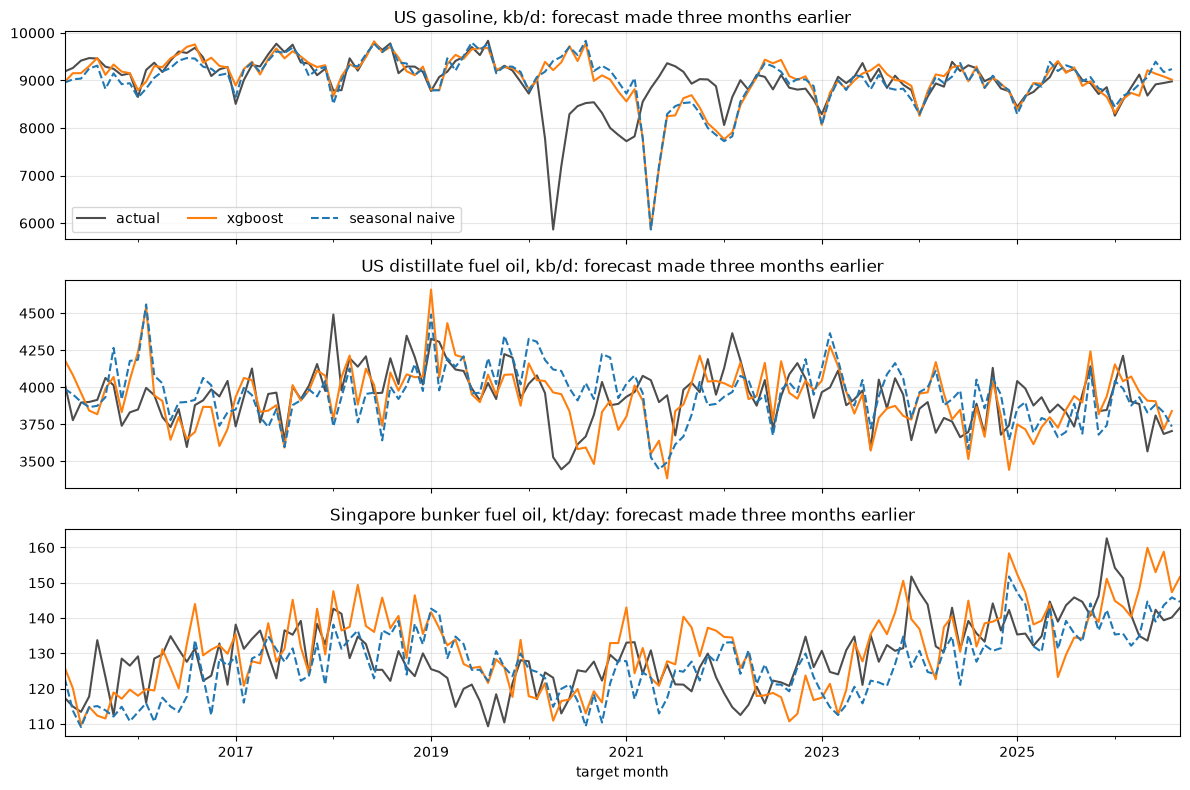

In [24]:
# actual against forecast, three months ahead
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, p in zip(axes, products):
    three = everything[(everything["product"] == p) & (everything["step"] == 3)].set_index("month")
    three["actual"].plot(ax=ax, color="0.3", label="actual")
    three["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
    three["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
    ax.set_title(f"{TITLES[p]}: forecast made three months earlier"); ax.set_xlabel("target month")
axes[0].legend(ncol=3)
plt.tight_layout();

product,bunker,distillate,gasoline
"origins where the model beat the naive, %",51.59,55.20,52.00


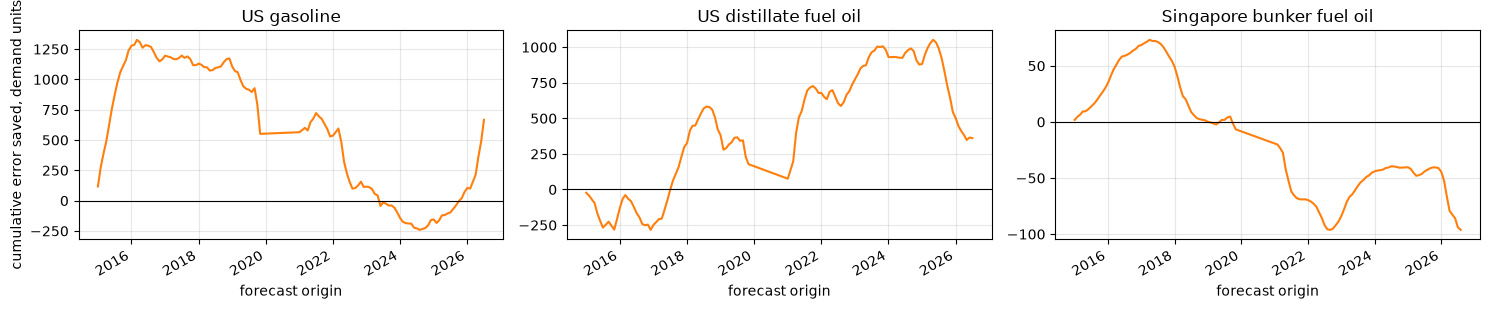

In [25]:
# where the model earns or loses against the naive: absolute error saved, cumulated over forecast origins.
# A rising line means the model is ahead, a falling line that the naive is
saved = (marked["naive"] - marked["actual"]).abs() - (marked["xgboost"] - marked["actual"]).abs()
saved = saved.groupby([marked["product"], marked["origin"]]).mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, p in zip(axes, products):
    saved[p].cumsum().plot(ax=ax, color="C1")
    ax.axhline(0, color="k", lw=.8); ax.set_title(TITLES[p].split(",")[0]); ax.set_xlabel("forecast origin")
axes[0].set_ylabel("cumulative error saved, demand units")
plt.tight_layout();
(saved > 0).groupby("product").mean().mul(100).rename("origins where the model beat the naive, %").to_frame().T

- **No regime in which the model is reliably better.** It wins 8 years of 12 on gasoline and distillate and 6 of 12 on bunker, and about half of the individual origins (52%, 55%, 52%).
- **2020-21 does not change the ranking.** With those forecasts kept, the average error becomes 3.75% against 3.93% for gasoline, 4.07% against 4.44% for distillate and 6.76% against 6.52% for bunker. Both forecasts miss a lockdown by about 15%; excluding the year from the headline hides no advantage of the benchmark.
- **The latest year is the worst for distillate**: 4.8% against 2.9% on the 2026 targets marked so far. A user of the model would have been better off with the naive this year.
- The cumulative lines show the same thing: gains arrive in episodes and are given back, with no steady drift upward.

## 7. Do the macro predictors help?

The honest version of feature importance is out-of-sample: rerun the backtest without a driver and see whether the error moves. Importance scores from the trees themselves say what the model used, not whether it helped, and neither says anything about causes.

To keep the cost down this test uses one origin per quarter and the same parameters. It is read against a yardstick: the same model with three other random seeds, which shows how much the score moves for no reason at all.

In [26]:
ablation = sql.query("SELECT * FROM ablation").pivot(index="variant", columns="product", values="wape")[products]
seeds = sql.query("SELECT * FROM seeds").pivot(index="seed", columns="product", values="wape")[products]

top = ["all drivers", "lags only", "seasonal naive"]
ablation = ablation.loc[top + sorted(ablation.index.difference(top))]
ablation  # WAPE %, quarterly origins

product,gasoline,distillate,bunker
variant,,,
all drivers,1.77,3.77,6.93
lags only,1.82,4.09,6.81
seasonal naive,1.83,3.84,6.77
without bunker_calls,NaN,NaN,6.98
without bunker_calls_gt,NaN,NaN,7.02
without cargo,NaN,NaN,6.99
without hdd,NaN,3.80,NaN
without hdd_oil,NaN,3.74,NaN
without inc,1.78,NaN,NaN


In [27]:
# change in WAPE against the full model: positive means the model is worse without the driver, so the driver helped
change = (ablation - ablation.loc["all drivers"]).drop(index=["all drivers", "seasonal naive"])
change.loc["seed noise (max - min over seeds)"] = seeds.max() - seeds.min()
change

product,gasoline,distillate,bunker
variant,,,
lags only,0.06,0.33,-0.12
without bunker_calls,NaN,NaN,0.05
without bunker_calls_gt,NaN,NaN,0.09
without cargo,NaN,NaN,0.06
without hdd,NaN,0.03,NaN
without hdd_oil,NaN,-0.02,NaN
without inc,0.01,NaN,NaN
without ind,NaN,0.04,NaN
without ind_manuf,NaN,0.01,NaN


- **Distillate: the drivers help together, none helps alone.** With lags only the error rises from 3.77% to 4.09% (+0.33, against a seed noise of 0.05), and falls back below the seasonal naive only when the drivers are in. Yet removing any one of them moves the error by 0.06 at most: weather, industry and the weekly EIA figure overlap, and the trees substitute one for another.
- **Gasoline: nothing to see.** Lags only costs 0.06, about the seed noise; payrolls is the only driver whose removal is visible (+0.08).
- **Bunker: the drivers hurt.** The model is better with lags only (-0.12) and without tanker arrivals (-0.11); world trade is the one driver that helps (+0.21). Port activity in the same month says little about bunker sales a year ahead.
- These are statements about forecast accuracy in this sample. They do not say that payrolls drive gasoline demand or that trade drives bunkering.

## 8. Current forecast

The same models fitted at the latest origin, with the parameters the backtest chose.

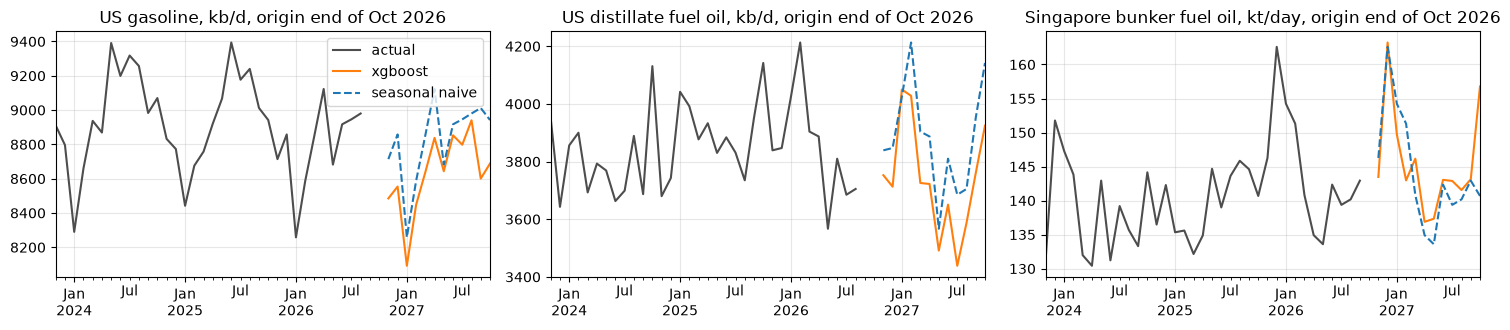

In [28]:
latest = {}
for p in products:
    last_origin = datasets[p].index[-1]
    latest[p] = pd.DataFrame({"xgboost": model.forecast(datasets[p], c.DEMAND_LAG[p], last_origin, model.tuned(p)),
                              "naive": model.seasonal_naive(datasets[p], c.DEMAND_LAG[p], last_origin)})

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, p in zip(axes, products):
    datasets[p]["demand"].iloc[-36:].plot(ax=ax, color="0.3", label="actual")
    latest[p]["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
    latest[p]["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
    ax.set_title(f"{TITLES[p]}, origin end of {datasets[p].index[-1]:%b %Y}"); ax.set_xlabel("")
axes[0].legend()
plt.tight_layout();

In [29]:
# the forecast as a deviation from the seasonal naive, in %: what the model adds to last year's shape
pd.DataFrame({p: 100 * (latest[p]["xgboost"] / latest[p]["naive"] - 1) for p in products}).T

,2026-11-01,2026-12-01,2027-01-01,2027-02-01,2027-03-01,2027-04-01,2027-05-01,2027-06-01,2027-07-01,2027-08-01,2027-09-01,2027-10-01
gasoline,-2.63,-3.43,-2.01,-1.62,-2.43,-3.12,-0.44,-0.72,-1.66,-0.44,-4.57,-2.84
distillate,-2.25,-3.48,0.62,-4.39,-4.57,-4.24,-2.12,-4.18,-6.69,-3.18,-4.85,-5.25
bunker,-1.91,0.40,-2.93,-5.51,3.81,1.45,2.80,0.49,2.52,0.98,0.14,11.44


From the end of October 2026 the model sits below the seasonal naive for both US products over the coming year, by 0.4% to 4.6% for gasoline and by up to 6.7% for distillate: it reads the recent year-on-year weakness and extends it. For bunker the adjustments are small and of mixed sign, apart from +11% at twelve months, a single step that the backtest gives no reason to trust.

Given section 6, the first two or three months of the US adjustments are the part with some support in the backtest. Beyond six months the seasonal naive is the better number to quote.

## 9. Limitations

- **Not a vintage backtest.** Publication delays are respected, revisions are not: the model trains and is marked on today's version of each series (notebook 01, section 5). A forecaster at the time had slightly noisier data.
- **Lags are conventions.** Rounded up to a month end and tested against one real download, they can be a few days off around a release date.
- **Small sample.** About 300 months and 130 forecast origins per product, with overlapping twelve-month targets: neighbouring errors are correlated, so the differences between forecasts are not tested formally and should be read as indications.
- **2020.** Excluded from training and from the headline scores by an explicit rule set before the backtest; the by-year table shows what happens when it is kept.
- **One benchmark family.** Seasonal naive and last value. An ETS or SARIMA model would be a fairer statistical rival and may well beat both.
- **Apparent consumption.** EIA product supplied is a disappearance measure, not end-user demand; MPA sales are one port.
- **Predictive, not causal.** The driver test says which inputs improved forecasts in this sample, not what moves demand.

## 10. Conclusion

A gradient-boosted tree fed lagged demand and macro predictors does **not** forecast monthly refined-product demand twelve months ahead better than a simple time series. On the two US products it matches the seasonal naive within noise, with a small and usable gain at one to two months that comes from recent demand and, for distillate, from the drivers taken together. On Singapore bunker fuel oil it loses to the last published value at every horizon but one.

For a desk this says where to spend effort. The published month is two months old for EIA data, so the value is in the nowcast: the weekly figures and fast indicators that describe the months not yet published. A twelve-month view is better served by last year's shape, or by a structural balance, than by a model trained on some 250 monthly rows.

Next steps that could change the answer: a statistical benchmark (ETS or SARIMA) as a second rival, real vintages as the database accumulates them, and faster activity data for the horizons where the model already helps.